<a href="https://colab.research.google.com/github/Banuka2540/Pytorch-Learning-/blob/main/Customer_Curn_Prediction(ANN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# lets first install kagglehub
!pip install kagglehub

In [2]:
import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [3]:
import os

print(os.listdir(path))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [4]:
import pandas as pd
import os

file_path = os.path.join(
    path,
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

data = pd.read_csv(file_path)

data.sample(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6990,0376-OIWME,Male,0,Yes,No,36,Yes,No,Fiber optic,Yes,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,93.60,3366.05,No
6415,8224-UAXBZ,Female,0,Yes,No,58,No,No phone service,DSL,Yes,...,No,No,Yes,No,One year,Yes,Electronic check,45.35,2540.1,No
1254,9220-ZNKJI,Female,1,Yes,No,55,Yes,No,Fiber optic,No,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),88.80,4805.3,No
4076,1325-USMEC,Male,0,Yes,No,70,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,No,Two year,Yes,Credit card (automatic),99.35,6944.5,No
2813,6484-LATFU,Male,0,No,No,68,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,24.55,1657.4,No
3024,8735-NBLWT,Male,0,No,Yes,9,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.40,184.1,No
3905,5759-RCVCB,Female,0,No,No,3,No,No phone service,DSL,No,...,No,No,Yes,No,Month-to-month,No,Credit card (automatic),35.20,108.95,Yes
4165,9741-YLNTD,Male,0,No,No,6,Yes,Yes,Fiber optic,No,...,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),87.95,522.35,No
1223,1618-CFHME,Female,0,No,No,2,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,75.90,143.35,Yes
4358,6253-WRFHY,Male,0,Yes,Yes,13,Yes,No,DSL,No,...,No,No,Yes,Yes,One year,Yes,Electronic check,64.75,877.35,No


In [13]:
print("Dataset shape:", data.shape)
data.info()

Dataset shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [6]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
# Numerical columns
numerical_columns = data.select_dtypes(
    include=["int64", "float64"]
).columns
print(numerical_columns)


Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')


In [12]:
# Categorical columns
categorical_columns = data.select_dtypes(
    include=["object"]
).columns
print(categorical_columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')


In [15]:
data.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [18]:
missing_percentage = (data.isnull().sum() / len(data)) * 100

print(missing_percentage)

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64


In [20]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [22]:
print(data["TotalCharges"].dtype)

object


In [23]:
# Convert TotalCharges into numerical values
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Check missing values again
print(data["TotalCharges"].isnull().sum())

11


In [25]:
data.sample(4)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [27]:
print(data["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [28]:
print(data["Churn"].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


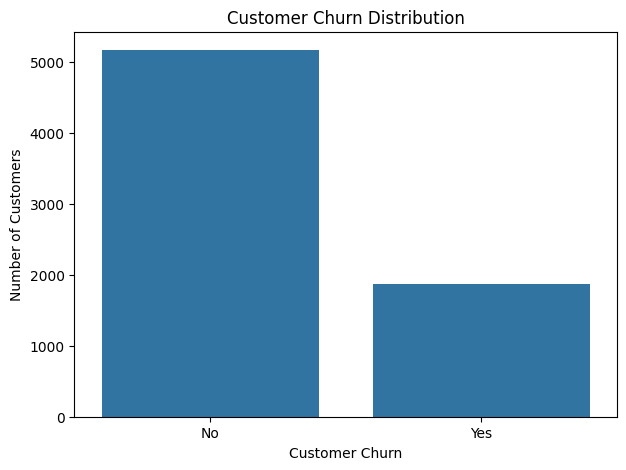

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

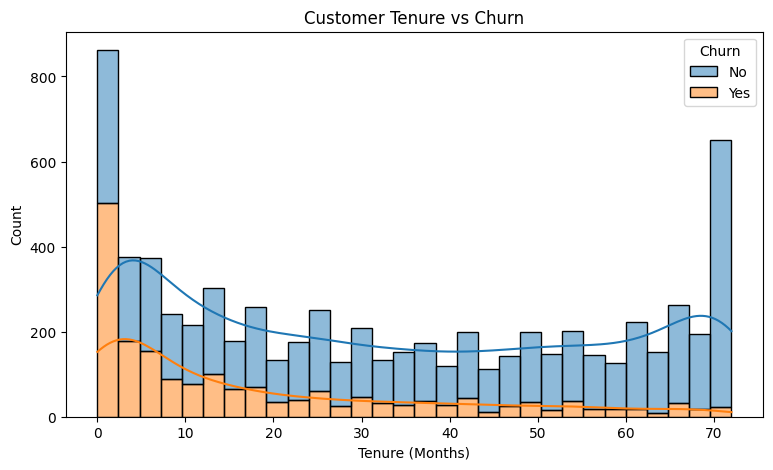

In [31]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")

plt.show()

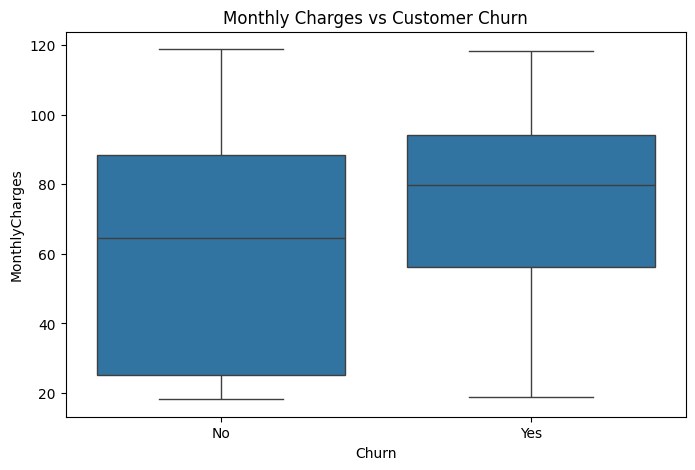

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")

plt.show()

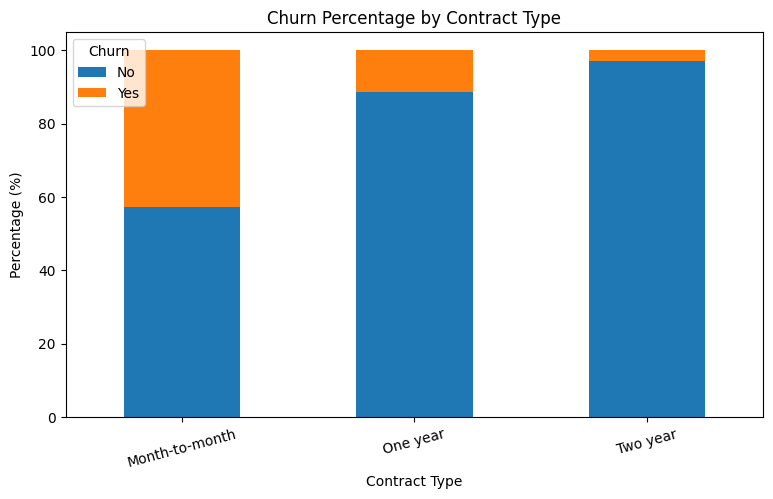

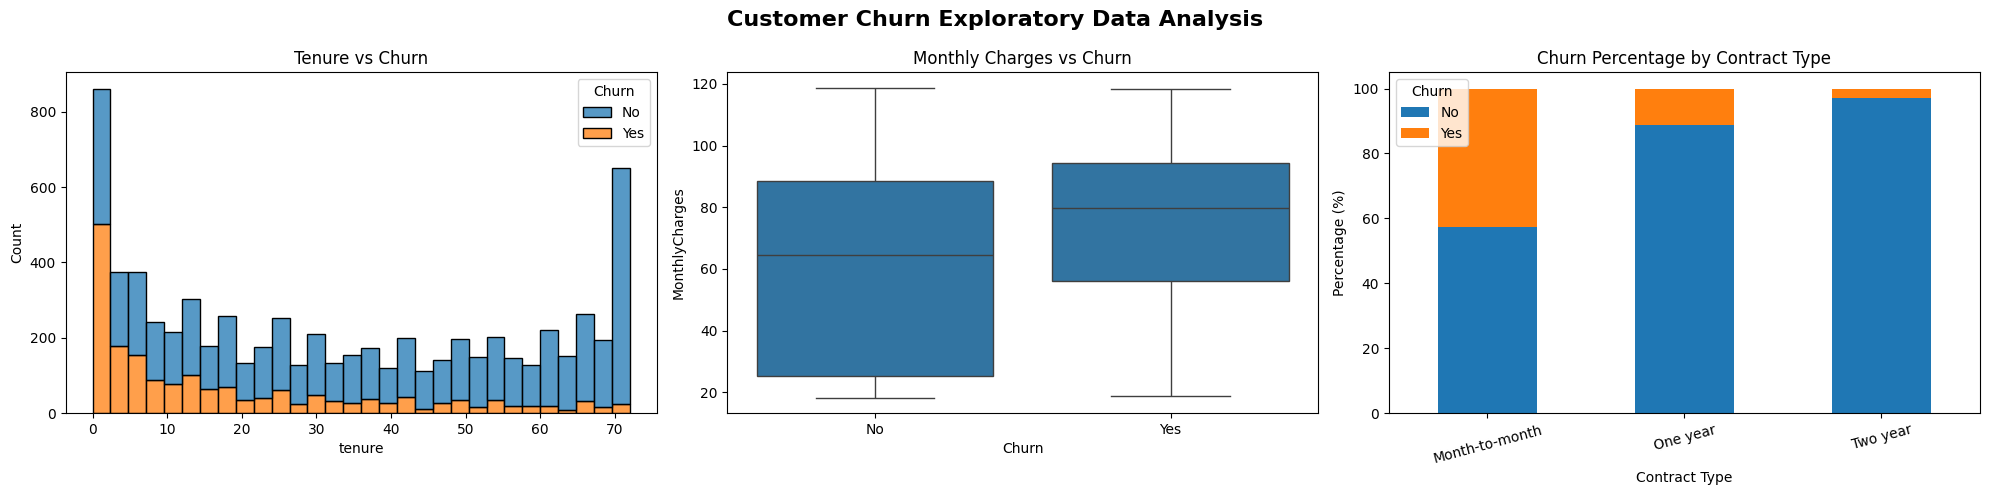

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Graph 1: Tenure vs Churn
sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack",
    ax=axes[0]
)
axes[0].set_title("Tenure vs Churn")

# Graph 2: Monthly Charges vs Churn
sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges",
    ax=axes[1]
)
axes[1].set_title("Monthly Charges vs Churn")

# Graph 3: Contract Type vs Churn
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

contract_churn.plot(
    kind="bar",
    stacked=True,
    ax=axes[2]  # Important!
)

axes[2].set_title("Churn Percentage by Contract Type")
axes[2].set_xlabel("Contract Type")
axes[2].set_ylabel("Percentage (%)")
axes[2].tick_params(axis="x", rotation=15)
axes[2].legend(title="Churn")

# Main title
fig.suptitle(
    "Customer Churn Exploratory Data Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()